# Batch decode: throughput vs concurrency

1. Previous results
2. Experiment design
3. Gemma 4 E2B: 64 requests, 256 output tokens
   - Time to finish 64 requests
   - Decode step vs batch size
   - Output length: 128 vs 256 tokens
   - Decode step across runs
4. Qwen3-4B: batch size ≤ 4
   - Decode step vs batch size
   - `stream_interval`
5. Gemma 4 E2B vs Qwen3-4B: 8 requests
6. Notes
7. Not measured

## Previous results (reported in prefill_ttft.ipynb and decode_tpot.ipynb)

vllm-mlx, Apple M1 8 GB, 4-bit weights, one request at a time (continuous batching off). n = prompt tokens.

| Model | Prefill b (ms/token) | TPOT(n) = a + β·n | Weights read per decode step |
|---|---|---|---|
| Qwen3-4B | 6.2 | 42.4 ms + 2.80 µs·n | 2.1 GB |
| Gemma 4 E2B | 0.86 | 26.4 ms + 0.39 µs·n | 1.31 GB |

- Decode at one request reads the weights once per token at ~50 GB/s (M1 peak ~68 GB/s).
- With B requests batched, one step reads the weights once for all B. Expected step time: weight read + B × (KV read + compute), so throughput should rise with B until compute-bound.

This notebook measures decode with several requests in flight.

## Experiment design

Same data, prompt and parsers as the TPOT experiment. Changes:

| | TPOT experiment | Current experiment |
|---|---|---|
| Continuous batching | off | on, `max_num_seqs` ≥ concurrency |
| Noise headlines | 50–750 | 0: signal headlines only, 286–292 prompt tokens |
| `max_tokens` | 2, 16, 32, 64, 128 | 2 and k (128 or 256) |
| Requests per point (N) | 1 | 8, 16, 32 or 64 |
| Concurrency (C) | 1 | 1–64 |

Short prompt so decode dominates. Prefix cache off, a uuid at the front of each system prompt which busts the cache. 1 warm-up request per run.

**Measurement**: N requests per point, at most C in flight (client-side aysncio.Semaphore controls no. of requests in flight); the next request is sent when one finishes. `start_s` is the send time from the start of the point; `e2e_s` runs from send to token k (`prefill_only: true`). Requests in a batch decode in lockstep and finish on the same step, so they are sent and finish in groups of C.

- Workload time: `max(start_s + e2e_s)` per point. End-to-end throughput: `N·k / workload time`.
- Decode step at batch size B = C, from the first group (sent at t = 0): `(batch time at k − batch time at 2) / (k − 2)`, batch time = max `e2e_s` in the group. Decode throughput: `B / step`.
- Prefill is compute-bound and does not batch; a group gets no decode step until all its prompts are prefilled.

## Gemma 4 E2B: 64 requests, 256 output tokens

`mlx-community/Gemma4-E2B-IT-Text-int4`. vllm-mlx loads it on its multimodal path (`MLLMBatchGenerator`).

| Data | Config |
|---|---|
| [`results/vllm-mlx/batch-decode-sweep-k256-gemma4-e2b-wmt.csv`](results/vllm-mlx/batch-decode-sweep-k256-gemma4-e2b-wmt.csv) | [`configs/vllm-mlx/batch-decode-sweep-k256-gemma4-e2b-wmt.yaml`](configs/vllm-mlx/batch-decode-sweep-k256-gemma4-e2b-wmt.yaml) |

N = 64, k = 256, C = 1, 2, 4, 8, 16, 32, 64, `max_num_seqs` 64, 3 repeats.

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

R = "results/vllm-mlx/"


def load(name):
    """Valid rows of one result file. Files from before run.requests existed have no
    start_s: every request in a point was sent at t = 0."""
    df = pd.read_csv(R + name + ".csv")
    if "start_s" not in df:
        df["start_s"] = 0.0
    df = df[df.ok & (df.completion_tokens >= df.max_tokens)].copy()
    df["end_s"] = df.start_s + df.e2e_s
    return df


def workload(df, k):
    """Per (concurrency, rep): requests and time to finish all of them, at max_tokens k."""
    g = df[df.max_tokens == k].groupby(["concurrency", "rep"])
    return pd.DataFrame({"requests": g.size(), "wall_s": g.end_s.max()})


def batch_step(df, k):
    """Decode step (ms) of the first batch of each point, i.e. the requests sent at t = 0:
    (batch time at max_tokens k - batch time at max_tokens 2) / (k - 2)."""
    first = df[df.start_s < 0.5].groupby(["concurrency", "rep", "max_tokens"]).e2e_s.max().unstack()
    return ((first[k] - first[2]) / (k - 2) * 1e3).rename("step_ms")


def summary(s):
    """mean/min/max over repeats, per concurrency."""
    return s.groupby("concurrency").agg(["mean", "min", "max"])


g256 = load("batch-decode-sweep-k256-gemma4-e2b-wmt")
print(g256.run_at.unique()[0], len(g256), "valid rows")

2026-11-08T17:42:03 2688 valid rows


### Time to finish 64 requests

Mean, min and max over 3 repeats. `prefill_only_s`: the same workload at `max_tokens` 2.

In [14]:
N, K = 64, 256
w = summary(workload(g256, K).wall_s)
w["speedup"] = w["mean"].iloc[0] / w["mean"]
w["tok_per_s"] = N * K / w["mean"]
w["prefill_only_s"] = workload(g256, 2).groupby("concurrency").wall_s.mean()
w.round(2)

,mean,min,max,speedup,tok_per_s,prefill_only_s
concurrency,,,,,,
1,512.25,511.21,513.09,1.00,31.98,63.97
2,341.26,340.76,342.01,1.50,48.01,63.22
4,318.06,317.95,318.18,1.61,51.51,62.59
8,299.81,299.31,300.71,1.71,54.65,62.67
16,199.92,199.73,200.09,2.56,81.95,62.22
32,145.77,145.49,146.14,3.51,112.39,62.94
64,142.68,142.56,142.85,3.59,114.83,61.04


- At concurrency=64: 3.6× from serial. Concurrency 32 and 64 take the same time (146 s, 143 s).
- The `max_tokens` 2 workload takes 61–64 s at every concurrency: prefill does not batch.
- Prefill is 12% of the workload time at concurrency 1 and 43% at 32 and 64.

### Decode step (exclude prefill time) vs batch size

In [15]:
s = summary(batch_step(g256, K))
B = pd.Series(s.index, index=s.index)
s["decode_tok_per_s"] = B / (s["mean"] / 1e3)
s["decode_speedup"] = s.decode_tok_per_s / s.decode_tok_per_s.iloc[0]
s["added_per_request_ms"] = s["mean"].diff() / B.diff()
s.round(1)

,mean,min,max,decode_tok_per_s,decode_speedup,added_per_request_ms
concurrency,,,,,,
1,27.8,27.6,28.2,36.0,1.0,NaN
2,34.3,34.0,34.8,58.3,1.6,6.5
4,62.7,62.7,62.9,63.8,1.8,14.2
8,116.5,116.1,116.9,68.7,1.9,13.4
16,135.3,135.1,135.4,118.3,3.3,2.3
32,163.5,160.5,165.8,195.7,5.4,1.8
64,321.5,320.6,323.0,199.1,5.5,4.9


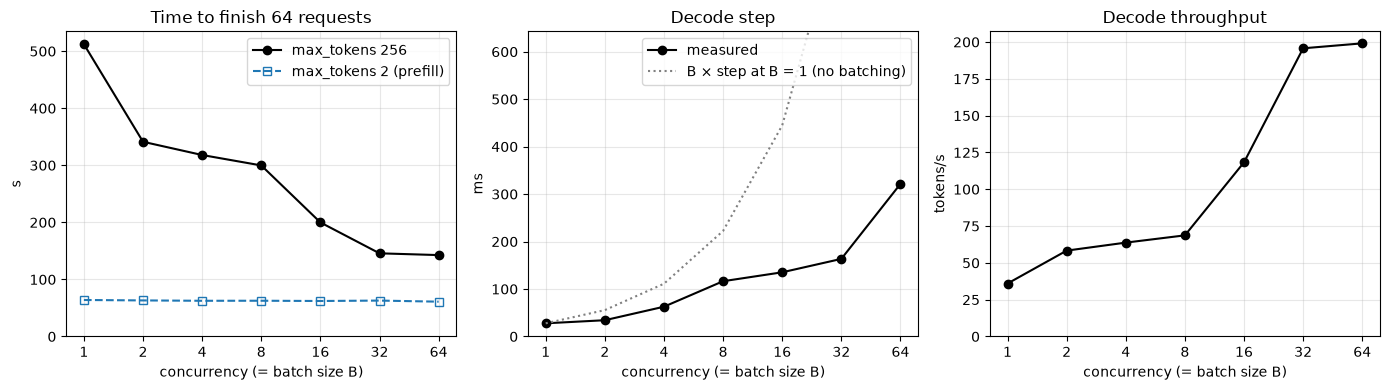

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ax = axes[0]
ax.plot(w.index, w["mean"], "ko-", label=f"max_tokens {K}")
ax.plot(w.index, w.prefill_only_s, "s--", mfc="none", label="max_tokens 2 (prefill)")
ax.set(title=f"Time to finish {N} requests", ylabel="s", ylim=(0, None))
ax = axes[1]
ax.plot(s.index, s["mean"], "ko-", label="measured")
ax.plot(s.index, s.index * s["mean"].iloc[0], ":", c="gray", label="B × step at B = 1 (no batching)")
ax.set(title="Decode step", ylabel="ms", ylim=(0, 2 * s["mean"].max()))
ax = axes[2]
ax.plot(s.index, s.decode_tok_per_s, "ko-")
ax.set(title="Decode throughput", ylabel="tokens/s", ylim=(0, None))
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(w.index, w.index)
    ax.set_xlabel("concurrency (= batch size B)")
    ax.grid(alpha=0.3)
for ax in axes[:2]:
    ax.legend()
fig.tight_layout();

| B | Added per extra request |
|---|---|
| 1 → 2 | 6.5 ms |
| 2 → 8 | 13–14 ms |
| 8 → 32 | 1.8–2.3 ms |
| 32 → 64 | 4.9 ms: step doubles with B |

- Decode throughput: 36 tokens/s at B = 1, 69 at 8, 196 at 32, 199 at 64. Ceiling ~200 tokens/s at B ≈ 32, 5.5× B = 1.
- Above B = 32 throughput is flat and each request's time per token grows in proportion to B.
- Expected per-request cost from bytes: KV read ~8 MB per sequence at this length, < 1 ms. B ≤ 8 is far above that; B = 8–32 is close to it.

### Output length: 128 vs 256 tokens

Earlier sweep: [`results/vllm-mlx/batch-decode-sweep-gemma4-e2b-wmt.csv`](results/vllm-mlx/batch-decode-sweep-gemma4-e2b-wmt.csv), N = 32, k = 128, C = 1–32, 2 repeats, run 2026-11-08T14:30. Prefill share: workload time at `max_tokens` 2 / workload time at k.

In [17]:
g128 = load("batch-decode-sweep-gemma4-e2b-wmt")
cmp = {}
# k is the number of max_tokens property of the request to vllm server, 
# controls the output tokens generated but doesn't include thinking tokens
for k, df in [(128, g128), (256, g256)]:
    wk = workload(df, k).groupby("concurrency").wall_s.mean()
    w2 = workload(df, 2).groupby("concurrency").wall_s.mean()
    cmp[f"speedup k={k}"] = wk.iloc[0] / wk
    cmp[f"prefill share k={k}"] = w2 / wk
    cmp[f"step_ms k={k}"] = batch_step(df, k).groupby("concurrency").mean()
pd.DataFrame(cmp).round(2)

,speedup k=128,prefill share k=128,step_ms k=128,speedup k=256,prefill share k=256,step_ms k=256
concurrency,,,,,,
1,1.00,0.22,27.57,1.00,0.12,27.79
2,1.42,0.31,33.89,1.50,0.19,34.29
4,1.52,0.33,62.35,1.61,0.20,62.74
8,1.60,0.35,115.00,1.71,0.21,116.47
16,2.20,0.48,134.59,2.56,0.31,135.26
32,2.76,0.59,167.90,3.51,0.43,163.50
64,NaN,NaN,NaN,3.59,0.43,321.46


- Decode step does not depend on k: within 1.5 ms for B ≤ 16, 4.4 ms (3%) at B = 32.
- Speedup at concurrency 32: 2.76× at k = 128, 3.51× at k = 256. The difference is prefill: 59% vs 43% of workload time.

### Decode step across runs

Four Gemma runs on 2026-11-08: N = 8 (12:27), N = 16 with `max_num_seqs` 16 (12:44), the k = 128 sweep (14:30), the k = 256 sweep (17:42).

In [18]:
runs = {
    "requests8, k=128": load("batch-decode-requests8-gemma4-e2b-wmt"),
    "requests16, k=128": load("batch-decode-requests16-gemma4-e2b-wmt"),
    "sweep, k=128": g128,
    "sweep-k256, k=256": g256,
}
rep = pd.DataFrame({name: batch_step(df, int(name.split("k=")[1])).groupby("concurrency").mean() for name, df in runs.items()})
rep.round(1)

,"requests8, k=128","requests16, k=128","sweep, k=128","sweep-k256, k=256"
concurrency,,,,
1,27.4,NaN,27.6,27.8
2,34.2,NaN,33.9,34.3
4,62.7,NaN,62.4,62.7
8,115.1,116.0,115.0,116.5
16,NaN,134.0,134.6,135.3
32,NaN,NaN,167.9,163.5
64,NaN,NaN,NaN,321.5


- Agreement within 1.5 ms (1.3%) for B ≤ 16, 4.4 ms (2.7%) at B = 32.

## Qwen3-4B: batch size ≤ 4

`mlx-community/Qwen3-4B-4bit`. vllm-mlx loads it on mlx-lm's `BatchGenerator`.

| Data | Config |
|---|---|
| [`results/vllm-mlx/batch-decode-test-qwen3-wmt.csv`](results/vllm-mlx/batch-decode-test-qwen3-wmt.csv) | [`configs/vllm-mlx/batch-decode-test-qwen3-wmt.yaml`](configs/vllm-mlx/batch-decode-test-qwen3-wmt.yaml) |
| [`results/vllm-mlx/batch-decode-test-qwen3-wmt-si8.csv`](results/vllm-mlx/batch-decode-test-qwen3-wmt-si8.csv) | [`configs/vllm-mlx/batch-decode-test-qwen3-wmt-si8.yaml`](configs/vllm-mlx/batch-decode-test-qwen3-wmt-si8.yaml) |

One batch of B requests per point (N = C), k = 128, C = 1, 2, 4, `max_num_seqs` 8, 2 repeats.

### Decode step vs batch size

In [19]:
q1 = load("batch-decode-test-qwen3-wmt")
q8 = load("batch-decode-test-qwen3-wmt-si8")
qs = pd.DataFrame({"stream_interval 1": batch_step(q1, 128), "stream_interval 8": batch_step(q8, 128)})
qm = summary(qs["stream_interval 1"])
QB = pd.Series(qm.index, index=qm.index)
qm["decode_tok_per_s"] = QB / (qm["mean"] / 1e3)
qm["added_per_request_ms"] = qm["mean"].diff() / QB.diff()
qm.round(1)

,mean,min,max,decode_tok_per_s,added_per_request_ms
concurrency,,,,,
1,42.6,42.6,42.6,23.5,NaN
2,61.4,59.1,63.8,32.5,18.8
4,124.2,116.0,132.5,32.2,31.4


- 42.6 ms at B = 1. Default-engine TPOT fit at this length: 42.4 + 2.80 µs × 286 = 43.2 ms. The batching engine adds no cost at B = 1.
- +19 ms per extra request from B = 1 to 2, +31 ms from 2 to 4. Decode throughput is flat at ~32 tokens/s from B = 2.
- B = 4 repeats differ by 14% (116 vs 133 ms).

### `stream_interval`

vllm-mlx `--stream-interval`: tokens per streamed chunk. Default 1: the server detokenises, parses and sends every token of every request. At 8 it sends one chunk per 8 tokens; the final chunk is always sent on finish, so the time stamps are unchanged.

Set by `server.stream_interval` in a config; omitted means 1. All runs in this notebook use 1 except [`batch-decode-test-qwen3-wmt-si8.csv`](results/vllm-mlx/batch-decode-test-qwen3-wmt-si8.csv) (8), which is identical to the test run otherwise.

In [20]:
qs.unstack("rep").round(1)

stream_interval 1        stream_interval 8       
rep                         0      1                 0      1
concurrency                                                  
1                        42.6   42.6              43.0   42.8
2                        59.1   63.8              65.6   65.7
4                       116.0  132.5             111.8  127.9

- Change from `stream_interval` 1 to 8: −4% to +11% per point, inside the 14% spread between repeats at B = 4. Per-token streaming and response parsing are not the per-request cost.
- No throughput gain from setting stream_interval 8, and it delays tokens to the client. All other runs keep stream_interval to default value of 1.

## Gemma 4 E2B vs Qwen3-4B: 8 requests

| Model | Data |
|---|---|
| Qwen3-4B | [`results/vllm-mlx/batch-decode-requests8-qwen3-wmt.csv`](results/vllm-mlx/batch-decode-requests8-qwen3-wmt.csv) |
| Gemma 4 E2B | [`results/vllm-mlx/batch-decode-requests8-gemma4-e2b-wmt.csv`](results/vllm-mlx/batch-decode-requests8-gemma4-e2b-wmt.csv) |

N = 8, k = 128, C = 1, 2, 4, 8, `max_num_seqs` 8, 3 repeats. The Qwen run has no `max_tokens` 2 rows, so its decode step comes from the test run above.

In [21]:
qw = load("batch-decode-requests8-qwen3-wmt")
gw = load("batch-decode-requests8-gemma4-e2b-wmt")
vs = {}
for name, df in [("Qwen3-4B", qw), ("Gemma 4 E2B", gw)]:
    wk = summary(workload(df, 128).wall_s)
    vs[(name, "wall_s")] = wk["mean"]
    vs[(name, "wall range")] = wk["min"].round(1).astype(str) + "–" + wk["max"].round(1).astype(str)
    vs[(name, "tok_per_s")] = 8 * 128 / wk["mean"]
    vs[(name, "speedup")] = wk["mean"].iloc[0] / wk["mean"]
vs = pd.DataFrame(vs)
vs.round(2)

Qwen3-4B                              Gemma 4 E2B             \
              wall_s wall range tok_per_s speedup      wall_s wall range   
concurrency                                                                
1              58.40  58.4–58.4     17.53    1.00       35.62  35.6–35.6   
2              48.74  48.6–48.9     21.01    1.20       25.16  25.1–25.2   
4              45.95  43.3–47.3     22.28    1.27       23.61  23.5–23.7   
8              45.85  43.7–46.9     22.33    1.27       22.32  22.3–22.4   

                               
            tok_per_s speedup  
concurrency                    
1               28.75    1.00  
2               40.70    1.42  
4               43.37    1.51  
8               45.87    1.60

In [22]:
gm = s.loc[[1, 2, 4, 8], ["mean", "decode_tok_per_s"]]
steps = pd.DataFrame({"Qwen3-4B step_ms": qm["mean"], "Gemma 4 E2B step_ms": gm["mean"],
                      "Qwen3-4B tok/s": qm.decode_tok_per_s, "Gemma 4 E2B tok/s": gm.decode_tok_per_s})
steps.round(1)

,Qwen3-4B step_ms,Gemma 4 E2B step_ms,Qwen3-4B tok/s,Gemma 4 E2B tok/s
concurrency,,,,
1,42.6,27.8,23.5,36.0
2,61.4,34.3,32.5,58.3
4,124.2,62.7,32.2,63.8
8,NaN,116.5,NaN,68.7


- Time for 8 requests at concurrency 8: Qwen3-4B 45.9 s (1.27× concurrency 1), Gemma 4 E2B 22.3 s (1.60×).
- Added per request from B = 2 to 4: Qwen3-4B 31 ms, Gemma 4 E2B 14 ms, ratio 2.2. Weights read per step: ratio 1.6.
- Decode throughput at B = 4: Qwen3-4B 32 tokens/s, Gemma 4 E2B 64 tokens/s.
- The two models run on different batch generators (mlx-lm `BatchGenerator`, vllm-mlx `MLLMBatchGenerator`). Model size and code path both differ.

## Notes

- **Cause of the per-request cost (not verified).** B ≤ 8 costs 13–14 ms per extra request on Gemma, ~half a weight read at 50 GB/s; B = 8–32 costs ~2 ms. Consistent with the 4-bit matmul kernel changing with row count: weights loaded and dequantised per row for small B, once per tile for large B. The step doubling from 32 to 64 is consistent with either a 32-row tile or the kernel reaching its compute limit. MLX kernel selection not checked.
- **Prefill at ~290 tokens.** Time to token 2 at B = 1: Qwen3-4B 1.97 s (prefill fit 1.8 s + one step), Gemma 4 E2B 1.0 s (prefill fit 0.25 s). The fit was made on 1.4k–21k tokens with no constant term; Gemma has ~0.7 s unaccounted for at this length, on this path. Not investigated.
- **Repeats.** Qwen3-4B repeat 0 is faster than later repeats at B = 4: 12% (decode step, test run), 9% (workload time, N = 8 run). Gemma 4 E2B repeats agree within 1%, 3% at B = 32.
- **Continuous admission.** In some Gemma `max_tokens` 2 groups one request finishes ~1 s after sending while the rest take the full group time: the scheduler prefills requests as they arrive. The next request is then sent early, out of step with its group.
- **Token count.** Gemma 4 E2B reports `completion_tokens` = `max_tokens` on this path; the default engine reported `max_tokens` + 2.

## Not measured

- Standalone 4-bit matmul time at B = 1–64: tests the kernel explanation.
- Qwen3-4B decode step at B ≥ 8.
- Long prompts: KV per sequence grows (Qwen3-4B 144 KiB/token, Gemma 4 E2B 14 KiB/token) and limits B.
- Staggered arrivals and mixed output lengths.